# 05 — Anomaly Detection: The League's Statistical Unicorns

**Project:** Positionless NBA Player Archetypes · **Season:** 2025-26 · **Population:** 379 players with ≥ 500 minutes

The clustering notebook gave every player an archetype, but two kinds of players fit their label poorly:

- **Border players** sit *between* two archetypes (silhouette near 0). Their profile is common; it just mixes two
  roles.
- **Statistical unicorns** sit *far from everyone*. Their combination of features is rare, so no archetype describes
  them well, even if they are formally closest to one.

These are different phenomena, and confusing them leads to wrong conclusions: a border player is *versatile*, a
unicorn is *unique*. This notebook measures "unusualness" in three complementary ways and then uses the silhouette
to separate the two kinds of players.

| Measure | Question it answers | Idea |
|---|---|---|
| **DBSCAN noise persistence** | How *isolated* is the player? | Increase ε step by step; the longer a player stays noise, the sparser their neighbourhood |
| **Distance to the archetype centroid** | How *atypical* is the player for their own archetype? | Euclidean distance from the player to the centre of their k-means cluster |
| **Extreme z-scores** | *Which* skill makes the player unusual? | Number of standard deviations from the league mean, feature by feature |
| **Silhouette** (from clustering) | Is the player *between* two archetypes? | s = (b − a) / max(a, b); near 0 = on a border |

**Feature space.** All anomaly measures use the **`StandardScaler`** version of the 13 style features. The scaling
analysis showed that the power transform deliberately compresses extreme players toward the centre, which is right for
clustering but wrong here: we *want* extreme players to stay extreme. As a bonus, standardised features are z-scores
directly. A robustness check against the power-transformed space is included (§6).

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from scipy.spatial.distance import cdist
from scipy.stats import spearmanr
from sklearn.cluster import DBSCAN

warnings.filterwarnings('ignore', category=UserWarning)
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 170)
pd.set_option('display.max_colwidth', 100)
sns.set_theme(style='whitegrid', context='notebook')

DATA = Path('../data') if Path('../data').exists() else Path('data')
MIN_SAMPLES = 6          # same DBSCAN density requirement as in the clustering notebook
TOP_SHARE = 0.05         # the most unusual 5% of players are flagged as anomalies
BORDER_SIL = 0.05        # silhouette threshold for border players (as in the clustering notebook)

---
## 1. Load Features and Archetypes

**Goal.** Load the standardised features (the anomaly space), the power-transformed features (for the robustness
check), the raw features (to describe players in real units) and the clustering results (archetype, silhouette,
border flag, DBSCAN labels, PCA coordinates).

**What to look for.** All tables row-aligned; standardised features with mean 0 and standard deviation 1, so every
value can be read directly as a z-score.

In [2]:
std = pd.read_csv(DATA / 'processed' / 'features_standard.csv')
power = pd.read_csv(DATA / 'processed' / 'features_power.csv')
raw = pd.read_csv(DATA / 'processed' / 'features_raw.csv')
arch = pd.read_csv(DATA / 'processed' / 'archetypes.csv')

META = ['player_id', 'player', 'team', 'pos', 'pos_played']     # identifiers + the two validation targets
FEAT = [c for c in std.columns if c not in META]
assert all((t['player_id'] == std['player_id']).all() for t in (power, raw, arch))
Z = std[FEAT].values
print('players:', Z.shape[0], '| features:', Z.shape[1])
print('mean range: %.3f … %.3f | std range: %.3f … %.3f' % (Z.mean(0).min(), Z.mean(0).max(), Z.std(0).min(), Z.std(0).max()))

players: 379 | features: 13
mean range: -0.000 … 0.000 | std range: 1.000 … 1.000


---
## 2. DBSCAN Noise Persistence

**Goal.** For every player, find the **smallest ε at which DBSCAN stops labelling them as noise**, with
`min_samples` fixed at 6. Call this value **ε-exit**.

**Why it measures isolation.** Increasing ε only ever *adds* neighbours, so once a player joins a cluster they never
return to noise. Players in crowded regions join at a small ε; players in sparse regions need a large one. The
ε-exit therefore ranks every player by how isolated they are, without having to choose a single ε.

**Computing it exactly.** A player *p* stops being noise as soon as either of the following holds:
1. *p* becomes a **core point**: at least `min_samples` players (including *p*) lie within ε. This happens at
   ε = k-dist(*p*), the distance to the `min_samples`-th closest player.
2. *p* becomes a **border point**: *p* lies within ε of some player *q* that is itself core. For a given *q*, both
   conditions hold from ε = max(d(*p*, *q*), k-dist(*q*)) onward.

So **ε-exit(*p*) = min( k-dist(*p*), min over *q* of max(d(*p*, *q*), k-dist(*q*)) )**. The single *q* (or *p* itself)
that achieves the minimum is the player's **controlling distance**: the one link that decides when the player joins a
cluster.

**What to look for.** First, that this formula agrees exactly with scikit-learn's DBSCAN on a grid of ε values. Then the
shape of the ε-exit distribution: a long right tail means a few players are far more isolated than everyone else.

In [3]:
D = cdist(Z, Z)                                         # player-to-player Euclidean distances
kdist = np.sort(D, axis=1)[:, MIN_SAMPLES - 1]          # column 0 is the player itself (distance 0)
via = np.maximum(D, kdist[None, :])                     # eps needed to be within reach of core player q
np.fill_diagonal(via, np.inf)
eps_exit = np.minimum(kdist, via.min(axis=1))
anchor = np.where(kdist <= via.min(axis=1), -1, via.argmin(axis=1))   # -1: player joins as a core point

# verification against scikit-learn
grid = np.round(np.arange(1.0, 6.01, 0.25), 2)
check = [(e, int(((DBSCAN(eps=e, min_samples=MIN_SAMPLES).fit_predict(Z) == -1) != (eps_exit > e)).sum()))
         for e in grid]
print('players whose noise label differs from sklearn, per ε:', {e: m for e, m in check})
print('exact formula matches sklearn at every ε:', all(m == 0 for _, m in check))

players whose noise label differs from sklearn, per ε: {np.float64(1.0): 0, np.float64(1.25): 0, np.float64(1.5): 0, np.float64(1.75): 0, np.float64(2.0): 0, np.float64(2.25): 0, np.float64(2.5): 0, np.float64(2.75): 0, np.float64(3.0): 0, np.float64(3.25): 0, np.float64(3.5): 0, np.float64(3.75): 0, np.float64(4.0): 0, np.float64(4.25): 0, np.float64(4.5): 0, np.float64(4.75): 0, np.float64(5.0): 0, np.float64(5.25): 0, np.float64(5.5): 0, np.float64(5.75): 0, np.float64(6.0): 0}
exact formula matches sklearn at every ε: True


**Goal.** Visualise how the league leaves the "noise" state as ε grows, and who stays noise the longest.

**How to read the right panel.** The curve counts how many players are still noise at each ε. It drops steeply while
the dense core of the league is connected, then flattens into a long tail. The players named on the tail are the
last to be absorbed, the most isolated profiles in the league.

**What to look for.** The ε at which most of the league has joined a cluster, and how far beyond that the last players
hold out.

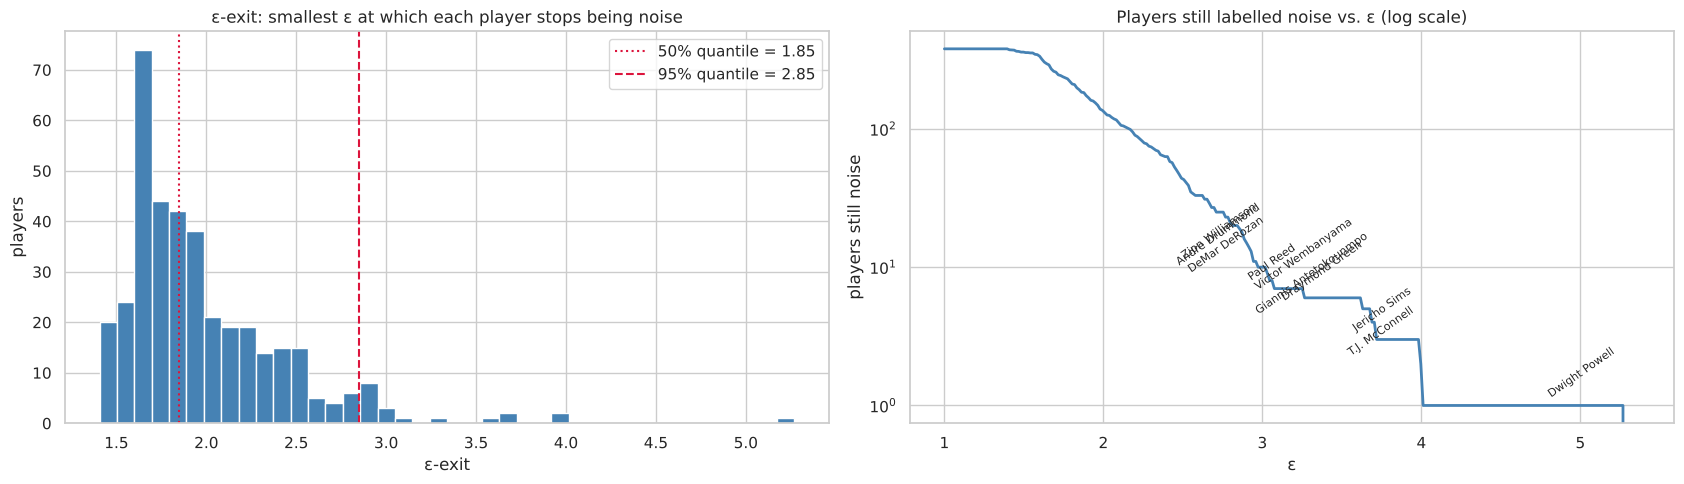

,player,archetype,ε-exit,joins as,controlling neighbour
270,Dwight Powell,Rim-Running Big,5.27,border point,Rudy Gobert
218,T.J. McConnell,Primary Creator,4.01,border point,Kevin Porter Jr.
313,Jericho Sims,Rim-Running Big,3.99,border point,Oso Ighodaro
10,Giannis Antetokounmpo,Hub Big,3.72,border point,Nikola Jokić
125,Draymond Green,Defensive Disruptor,3.68,border point,Lonzo Ball
357,Victor Wembanyama,Hub Big,3.62,border point,Chet Holmgren
282,Paul Reed,Hub Big,3.26,border point,Clint Capela
79,DeMar DeRozan,Primary Creator,3.06,border point,Brandon Ingram
89,Andre Drummond,Stretch Forward,3.04,border point,Kel'el Ware
373,Zion Williamson,Hub Big,3.02,border point,Nic Claxton


In [4]:
names = arch['player']
fig, ax = plt.subplots(1, 2, figsize=(17, 5))
ax[0].hist(eps_exit, bins=40, color='steelblue', edgecolor='white')
for q, ls in [(0.5, ':'), (0.95, '--')]:
    ax[0].axvline(np.quantile(eps_exit, q), color='crimson', ls=ls, label=f'{q:.0%} quantile = {np.quantile(eps_exit, q):.2f}')
ax[0].set(title='ε-exit: smallest ε at which each player stops being noise', xlabel='ε-exit', ylabel='players')
ax[0].legend()

e_grid = np.linspace(1.0, eps_exit.max() + 0.1, 300)
ax[1].plot(e_grid, [(eps_exit > e).sum() for e in e_grid], color='steelblue', lw=2)
ax[1].set_yscale('log')
for i in np.argsort(-eps_exit)[:10]:
    ax[1].annotate(names[i], (eps_exit[i], max((eps_exit > eps_exit[i] - 1e-9).sum(), 1)),
                   xytext=(-5, 6), textcoords='offset points', fontsize=8, rotation=35, ha='right')
ax[1].set(title='Players still labelled noise vs. ε (log scale)', xlabel='ε', ylabel='players still noise')
plt.tight_layout(); plt.show()

persist = pd.DataFrame({'player': names, 'archetype': arch['archetype'], 'ε-exit': eps_exit.round(2),
                        'joins as': np.where(anchor == -1, 'core point', 'border point'),
                        'controlling neighbour': [('— (own density)' if a == -1 else names[a]) for a in anchor]})
persist.nlargest(12, 'ε-exit')

### Findings: Noise persistence
- **The formula reproduces scikit-learn exactly** at every ε tested, so ε-exit is not an approximation: it is precisely
  the ε at which DBSCAN would first assign each player to a cluster.
- Half the league leaves noise by ε ≈ 1.9 and 95% by ε ≈ 2.9, but the tail stretches to **ε ≈ 5.3**: a handful of
  players are almost twice as isolated as the 95th-percentile player.
- **All twelve most persistent players join as border points**, through a single controlling neighbour. Their own
  neighbourhood never becomes dense, even at large ε; they are eventually attached to the closest core player.
- The controlling neighbour is a revealing comparison, *the most similar player the league has to offer*: Dwight Powell
  → Rudy Gobert, Giannis → Jokić, Wembanyama → Chet Holmgren, DeRozan → Brandon Ingram, Draymond Green → Lonzo Ball.
  The distances involved (ε-exit 3–5) show how loose even the best comparison is.

---
## 3. Distance to the Archetype Centroid

**Goal.** Measure how far each player sits from the **centre of their own archetype**.

**Why it complements persistence.** k-means assigns *every* player to a cluster, including players who are far from
all of them: an outlier is simply attached to the nearest centroid. Persistence measures isolation from *other
players*; centroid distance measures how badly the *assigned archetype* describes the player. A player can be
moderately isolated but still typical for their archetype, or vice versa.

**How it is computed.** Each archetype's centroid is the mean of its members in the standardised feature space; the
distance is the Euclidean norm of the difference between the player's feature vector and that centroid:

$$d_i = \lVert x_i - \mu_{c(i)} \rVert$$

Squaring and summing this over all players gives exactly the **inertia** of the clustering, so the players with the
largest *dᵢ* are the ones contributing most to the within-cluster spread.

**What to look for.** Archetypes that are tight (small distances) versus spread out, and the individual players far
above their archetype's typical distance.

top 5% of players (by distance) account for 16% of the total within-archetype sum of squares


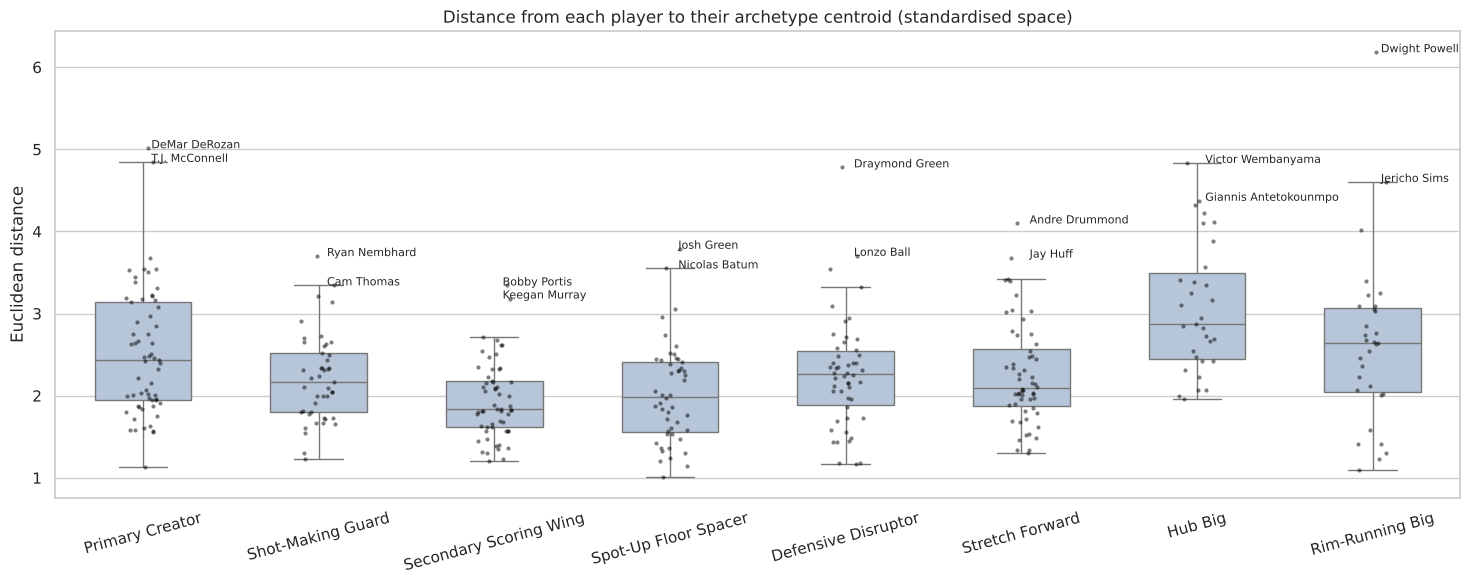

,median distance,max distance,farthest member
archetype,,,
Primary Creator,2.44,5.01,DeMar DeRozan
Shot-Making Guard,2.17,3.70,Ryan Nembhard
Secondary Scoring Wing,1.84,3.34,Bobby Portis
Spot-Up Floor Spacer,1.99,3.79,Josh Green
Defensive Disruptor,2.26,4.78,Draymond Green
Stretch Forward,2.09,4.10,Andre Drummond
Hub Big,2.88,4.83,Victor Wembanyama
Rim-Running Big,2.64,6.18,Dwight Powell


In [5]:
archetype = arch['archetype']
ORDER = ['Primary Creator', 'Shot-Making Guard', 'Secondary Scoring Wing', 'Spot-Up Floor Spacer',
         'Defensive Disruptor', 'Stretch Forward', 'Hub Big', 'Rim-Running Big']
centroids = pd.DataFrame(Z, columns=FEAT).groupby(archetype).mean()
d_cent = np.linalg.norm(Z - centroids.loc[archetype].values, axis=1)
share = (d_cent ** 2) / (d_cent ** 2).sum()
print(f'top 5% of players (by distance) account for {np.sort(share)[::-1][:int(round(0.05 * len(Z)))].sum():.0%} '
      f'of the total within-archetype sum of squares')

fig, ax = plt.subplots(figsize=(15, 6))
sns.boxplot(x=archetype, y=d_cent, order=ORDER, color='lightsteelblue', fliersize=0, width=0.55, ax=ax)
sns.stripplot(x=archetype, y=d_cent, order=ORDER, color='black', size=3, alpha=0.5, ax=ax)
for n in ORDER:
    m = np.where(archetype == n)[0]
    for i in m[np.argsort(-d_cent[m])[:2]]:
        ax.annotate(names[i], (ORDER.index(n), d_cent[i]), xytext=(6, 0), textcoords='offset points', fontsize=8)
ax.set(title='Distance from each player to their archetype centroid (standardised space)', xlabel='',
       ylabel='Euclidean distance')
plt.xticks(rotation=15); plt.tight_layout(); plt.show()

pd.DataFrame({'median distance': pd.Series(d_cent).groupby(archetype).median(),
              'max distance': pd.Series(d_cent).groupby(archetype).max(),
              'farthest member': pd.Series(d_cent).groupby(archetype).idxmax().map(names)}).loc[ORDER].round(2)

### Findings: Distance to centroid
- **Hub Big and Rim-Running Big are the most spread-out archetypes** (largest median distances). Both sit at the edge
  of the feature space, where players are few and differ a lot from one another. Secondary Scoring Wing is the tightest:
  its members are close to the league average and therefore close to each other.
- The farthest member of each archetype is often a well-known one-of-a-kind player, attached to the nearest
  centroid only because k-means must assign everyone somewhere.
- A small share of players accounts for a disproportionate share of the within-archetype sum of squares (printed
  above): the outliers that k-means is forced to absorb.

---
## 4. Extreme z-Scores: *Which* Skill Is Unusual?

**Goal.** Persistence and centroid distance say *how* unusual a player is; z-scores say *why*. For each player, find
the **largest absolute z-score** across the 13 features, which feature it is, and how many features exceed |z| ≥ 3.

**Why |z| ≥ 3?** If a feature were normally distributed, only about 0.3% of players would exceed it, roughly one
player in the whole league per feature. The style features are skewed, so more players cross it, but it remains a
clear marker of an extreme skill or habit.

**Two kinds of unusual.**
- **Extreme specialist:** at least one feature with |z| ≥ 3; one skill is far outside the league's normal range.
- **Rare combination:** no single extreme feature, but the *combination* of moderately unusual features puts the
  player far from everyone (high persistence and centroid distance with max |z| < 3).

**What to look for.** Which features produce the most extremes, and the z-score fingerprint of the most unusual
players.

In [6]:
absZ = np.abs(Z)
max_z = absZ.max(axis=1)
max_feat = np.array(FEAT)[absZ.argmax(axis=1)]
n_extreme = (absZ >= 3).sum(axis=1)
print(f'players with at least one |z| ≥ 3: {(max_z >= 3).sum()} | with |z| ≥ 4: {(max_z >= 4).sum()}')

ext = pd.DataFrame({'players with |z| ≥ 3': (absZ >= 3).sum(axis=0),
                    'max |z|': absZ.max(axis=0).round(2),
                    'most extreme player': [names[i] for i in absZ.argmax(axis=0)]}, index=FEAT)
ext.sort_values('players with |z| ≥ 3', ascending=False)

players with at least one |z| ≥ 3: 45 | with |z| ≥ 4: 9


,players with |z| ≥ 3,max |z|,most extreme player
rim_share,8,4.28,Mitchell Robinson
blk_percent,8,4.85,Victor Wembanyama
mid_share,7,5.00,DeMar DeRozan
orb_percent,7,4.72,Mitchell Robinson
ast_percent,5,3.98,Nikola Jokić
stl_percent,4,4.17,Dru Smith
usg_percent,3,3.37,Luka Dončić
corner3_rate,3,4.02,Josh Green
tov_percent,3,4.09,Jericho Sims
drb_percent,3,3.40,Victor Wembanyama


### Findings: z-score extremes
- **45 players (12%) have at least one feature with |z| ≥ 3**, and 9 have one with |z| ≥ 4. Extremes are far more
  common than a normal distribution would predict, a reminder that the style features are skewed.
- **Extremes come mostly from interior and specialist stats**: rim share and BLK% (8 players each), mid-range share and
  ORB% (7 each). The single most extreme value in the league is Dwight Powell's free-throw rate (z = +6.7: 1.11 free
  throws per field-goal attempt).
- **No player reaches |z| ≥ 3 on 3PA rate or on % of 2s assisted.** These features are bounded shares with a wide,
  well-populated spread, so nobody is far outside the range.

---
## 5. Combining the Measures: Unicorns vs. Border Players

### 5a. How do the measures relate?

**Goal.** Check how strongly the three anomaly measures agree with each other, and with the silhouette.

**What to look for.** The three anomaly measures should agree substantially (they all capture "far from others"), but
not perfectly (each captures a different aspect). The key question is the silhouette: if it were strongly negatively
correlated with the anomaly measures, unusual players and border players would be the same people. If it is roughly
uncorrelated, they are **two different phenomena**.

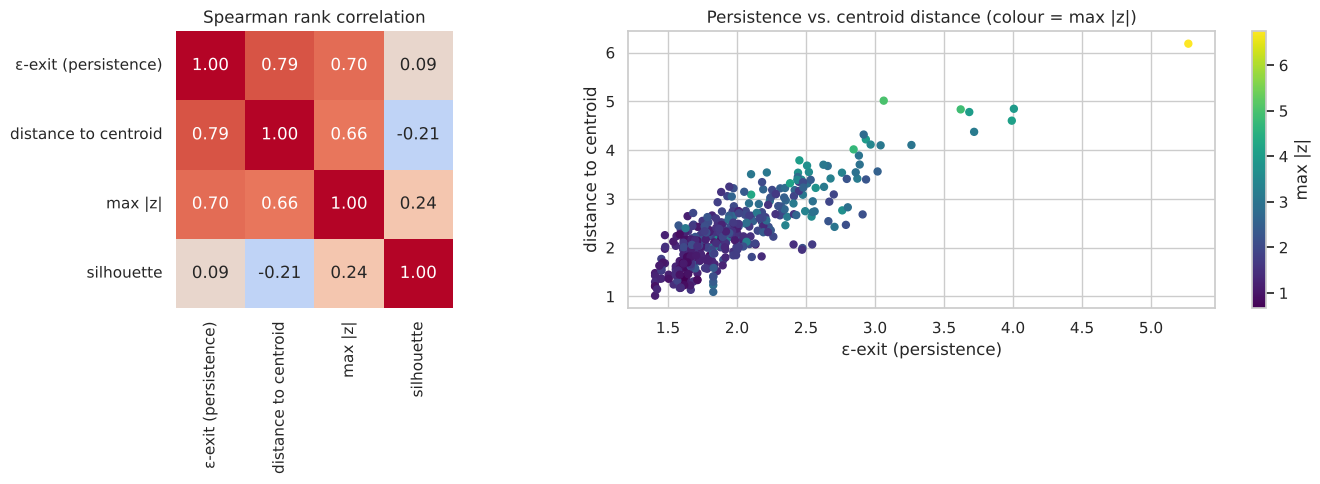

In [7]:
silhouette = arch['silhouette'].values
measures = pd.DataFrame({'ε-exit (persistence)': eps_exit, 'distance to centroid': d_cent,
                         'max |z|': max_z, 'silhouette': silhouette})
fig, ax = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={'width_ratios': [1, 1.25]})
sns.heatmap(measures.corr(method='spearman'), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1,
            cbar=False, ax=ax[0], square=True)
ax[0].set_title('Spearman rank correlation')
ax[1].scatter(eps_exit, d_cent, c=max_z, cmap='viridis', s=25)
ax[1].set(xlabel='ε-exit (persistence)', ylabel='distance to centroid',
          title='Persistence vs. centroid distance (colour = max |z|)')
plt.colorbar(ax[1].collections[0], ax=ax[1], label='max |z|')
plt.tight_layout(); plt.show()

### 5b. A single anomaly score

**Goal.** Combine the three measures into one **anomaly score**.

**Method.** The three measures are on different scales (ε units, distance units, z units), so each is first converted
to a **percentile rank** (0 = least unusual player in the league, 1 = most unusual). The anomaly score is the average
of the three ranks. Averaging ranks rather than raw values means no single measure dominates, and a player has to be
unusual on *several* measures to reach the top.

**Classification.** Combining the anomaly score with the silhouette gives four groups:

| | Silhouette ≥ 0.05 (clear archetype member) | Silhouette < 0.05 (between archetypes) |
|---|---|---|
| **Anomaly score in top 5%** | **Statistical unicorn**: far from everyone, yet closest to one archetype; an extreme version of a role | **Unique hybrid**: far from everyone *and* between two archetypes; fits no existing role |
| **Anomaly score below top 5%** | **Typical**: a standard member of their archetype | **Border player**: a common profile that mixes two neighbouring roles |

Unicorns are further split by their z-scores into **extreme specialists** (some |z| ≥ 3) and **rare combinations**
(no |z| ≥ 3).

**What to look for.** How many players fall in each group, and whether the two "unusual" groups contain different
people from the border players.

In [8]:
rank = lambda v: pd.Series(v).rank(pct=True).values
score = (rank(eps_exit) + rank(d_cent) + rank(max_z)) / 3
cut = np.quantile(score, 1 - TOP_SHARE)
is_anom = score >= cut
is_border = arch['border_player'].values          # silhouette < 0.05, exactly as flagged in the clustering notebook

category = np.select([is_anom & ~is_border, is_anom & is_border, ~is_anom & is_border],
                     ['Statistical unicorn', 'Unique hybrid', 'Border player'], 'Typical')
unicorn_type = np.where(category == 'Statistical unicorn',
                        np.where(max_z >= 3, 'extreme specialist', 'rare combination'), '')
print(f'anomaly-score threshold (top {TOP_SHARE:.0%}): {cut:.3f}')
pd.Series(category).value_counts().rename('players').to_frame()

anomaly-score threshold (top 5%): 0.929


,players
Typical,284
Border player,76
Statistical unicorn,17
Unique hybrid,2


### 5c. The map of unusualness

**Goal.** Plot every player by silhouette (x-axis: how clearly the player belongs to an archetype) against anomaly
score (y-axis: how unusual the player is overall), with the four groups marked.

**How to read it.** Numbers mark the top-5% players by rank (names listed on the right). The top-right quadrant holds the unicorns (unusual, but clearly closest to one archetype); the
top-left the unique hybrids; the bottom-left the border players; the bottom-right the typical players. If unusualness
and in-betweenness were the same thing, the points would lie along a diagonal from top-left to bottom-right.

**What to look for.** Whether the cloud follows that diagonal or fills the space, and which well-known players land
in each quadrant.

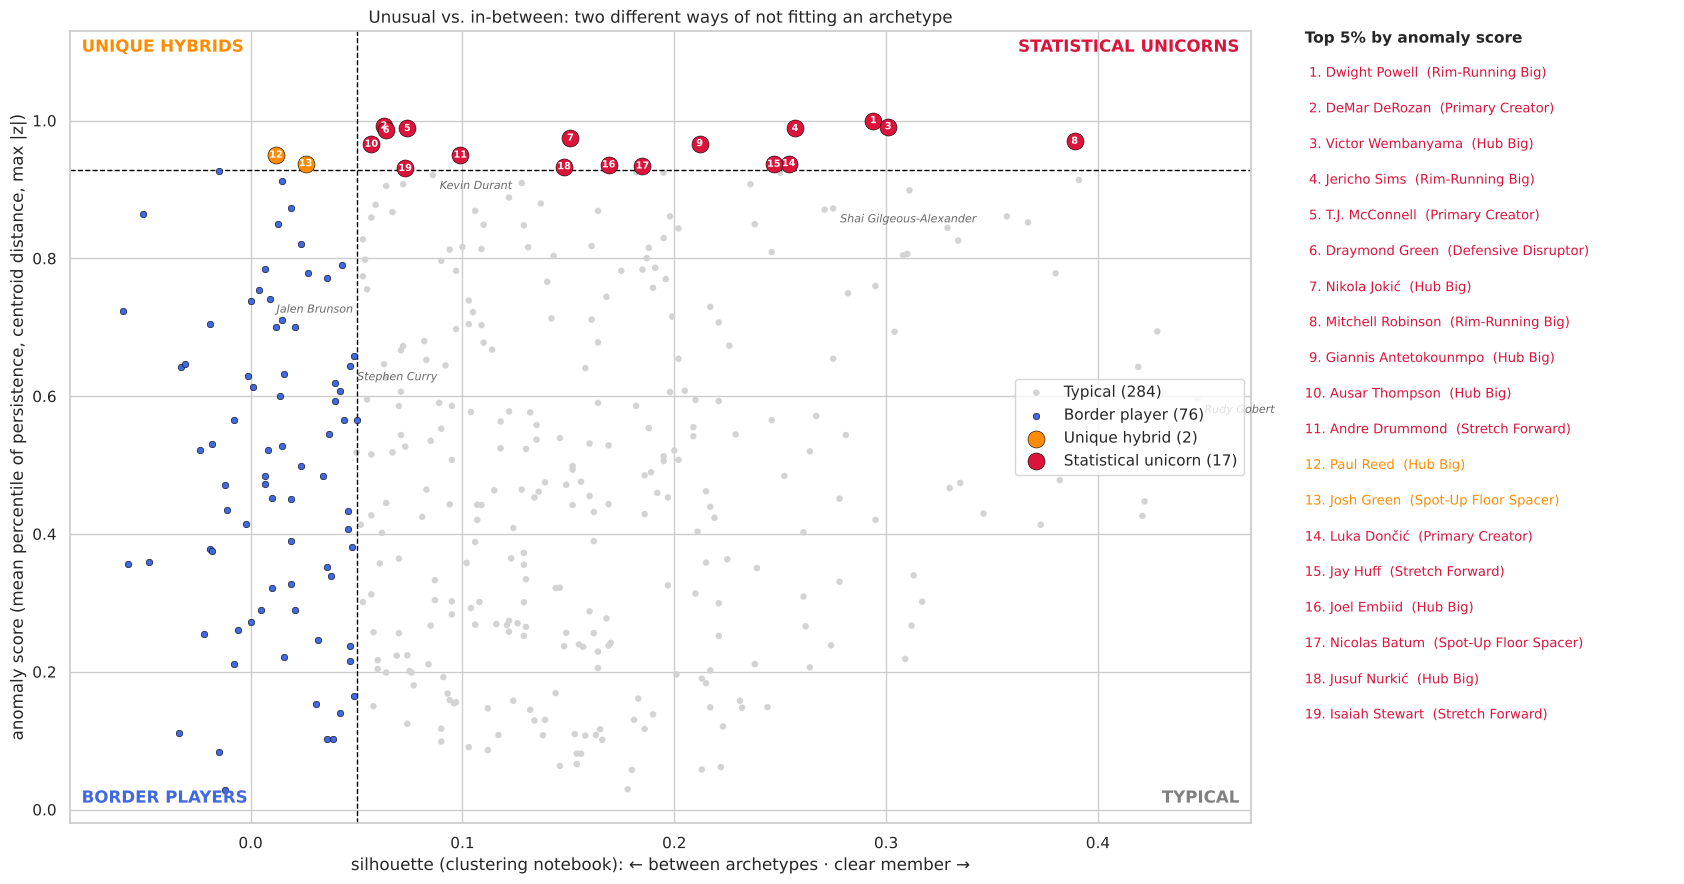

In [9]:
CAT_PAL = {'Statistical unicorn': 'crimson', 'Unique hybrid': 'darkorange', 'Border player': 'royalblue',
           'Typical': 'lightgrey'}
fig, (ax, side) = plt.subplots(1, 2, figsize=(17, 9), gridspec_kw={'width_ratios': [3.2, 1]})
for c in ['Typical', 'Border player', 'Unique hybrid', 'Statistical unicorn']:
    m = category == c
    big = c in ('Statistical unicorn', 'Unique hybrid')
    ax.scatter(silhouette[m], score[m], s=150 if big else 22, color=CAT_PAL[c], label=f'{c} ({m.sum()})',
               edgecolor='black' if c != 'Typical' else 'none', linewidth=0.4, zorder=3 if c != 'Typical' else 2)
ax.axhline(cut, color='black', ls='--', lw=1); ax.axvline(BORDER_SIL, color='black', ls='--', lw=1)
ranked = np.argsort(-score)[:is_anom.sum()]
for r, i in enumerate(ranked, 1):               # number each top-5% player by rank; names listed on the right
    ax.text(silhouette[i], score[i], str(r), ha='center', va='center', fontsize=7, color='white', weight='bold', zorder=5)
for s in ['Stephen Curry', 'Jalen Brunson', 'Kevin Durant', 'Rudy Gobert', 'Shai Gilgeous-Alexander']:
    i = np.where(names == s)[0][0]
    ax.annotate(s, (silhouette[i], score[i]), xytext=(5, -10), textcoords='offset points', fontsize=8,
                color='dimgrey', style='italic')
ax.set_ylim(-0.02, 1.13)
ax.text(0.99, 1.10, 'STATISTICAL UNICORNS', color='crimson', weight='bold', ha='right', transform=ax.get_yaxis_transform())
ax.text(0.01, 1.10, 'UNIQUE HYBRIDS', color='darkorange', weight='bold', transform=ax.get_yaxis_transform())
ax.text(0.01, 0.01, 'BORDER PLAYERS', color='royalblue', weight='bold', transform=ax.get_yaxis_transform())
ax.text(0.99, 0.01, 'TYPICAL', color='grey', weight='bold', ha='right', transform=ax.get_yaxis_transform())
ax.set(xlabel='silhouette (clustering notebook): ← between archetypes · clear member →',
       ylabel='anomaly score (mean percentile of persistence, centroid distance, max |z|)',
       title='Unusual vs. in-between: two different ways of not fitting an archetype')
ax.legend(loc='center right')
side.axis('off')
side.text(0, 1, 'Top 5% by anomaly score', weight='bold', va='top', fontsize=11)
for r, i in enumerate(ranked, 1):
    side.text(0, 1 - r * 0.045, f'{r:>2}. {names[i]}  ({archetype[i]})', va='top', fontsize=9.5,
              color=CAT_PAL[category[i]])
plt.tight_layout(); plt.show()

### 5d. The unicorns and unique hybrids, explained

**Goal.** For every player in the top 5%, show the three measures, the archetype, the controlling DBSCAN neighbour,
and the features with extreme z-scores, translated back into real units.

**What to look for.** Whether each player's "signature" features match what basketball knowledge says makes them
unusual.

In [10]:
LABEL = {'x3p_ar': '3PA rate', 'corner3_rate': 'corner-3 rate', 'mid_share': 'mid-range share',
         'rim_share': 'rim share', 'f_tr': 'FT rate', 'usg_percent': 'USG%', 'ast_percent': 'AST%',
         'tov_percent': 'TOV%', 'percent_assisted_x2p_fg': '% 2s assisted', 'orb_percent': 'ORB%',
         'drb_percent': 'DRB%', 'blk_percent': 'BLK%', 'stl_percent': 'STL%'}

def signature(i, k=3):
    top = np.argsort(-absZ[i])[:k]
    return ', '.join(f'{LABEL[FEAT[j]]} {raw.loc[i, FEAT[j]]:.2f} (z {Z[i, j]:+.1f})' for j in top)

top_idx = np.argsort(-score)[:is_anom.sum()]
table = pd.DataFrame({'player': names[top_idx].values, 'pos': arch['pos'][top_idx].values,
                      'archetype': archetype[top_idx].values, 'category': category[top_idx],
                      'type': unicorn_type[top_idx], 'score': score[top_idx].round(3),
                      'ε-exit': eps_exit[top_idx].round(2), 'dist': d_cent[top_idx].round(2),
                      'max |z|': max_z[top_idx].round(1), 'silhouette': silhouette[top_idx].round(2),
                      'closest comparable (DBSCAN)': [('—' if anchor[i] == -1 else names[anchor[i]]) for i in top_idx],
                      'signature (raw value, z)': [signature(i) for i in top_idx]})
table

,player,pos,archetype,category,type,score,ε-exit,dist,max |z|,silhouette,closest comparable (DBSCAN),"signature (raw value, z)"
0,Dwight Powell,C,Rim-Running Big,Statistical unicorn,extreme specialist,1.000,5.27,6.18,6.7,0.29,Rudy Gobert,"FT rate 1.11 (z +6.7), rim share 0.68 (z +2.8), TOV% 21.40 (z +2.8)"
1,DeMar DeRozan,PF,Primary Creator,Statistical unicorn,extreme specialist,0.992,3.06,5.01,5.0,0.06,Brandon Ingram,"mid-range share 0.58 (z +5.0), TOV% 7.40 (z -1.5), 3PA rate 0.15 (z -1.4)"
2,Victor Wembanyama,C,Hub Big,Statistical unicorn,extreme specialist,0.991,3.62,4.83,4.8,0.30,Chet Holmgren,"BLK% 9.40 (z +4.8), DRB% 33.90 (z +3.4), USG% 32.40 (z +2.3)"
3,Jericho Sims,C,Rim-Running Big,Statistical unicorn,extreme specialist,0.989,3.99,4.60,4.1,0.26,Oso Ighodaro,"TOV% 25.80 (z +4.1), rim share 0.82 (z +3.6), 3PA rate 0.00 (z -2.1)"
4,T.J. McConnell,PG,Primary Creator,Statistical unicorn,extreme specialist,0.989,4.01,4.85,3.9,0.07,Kevin Porter Jr.,"AST% 50.00 (z +3.9), mid-range share 0.47 (z +3.8), STL% 2.80 (z +1.9)"
5,Draymond Green,PF,Defensive Disruptor,Statistical unicorn,extreme specialist,0.986,3.68,4.78,4.0,0.06,Lonzo Ball,"TOV% 25.50 (z +4.0), % 2s assisted 0.84 (z +1.7), AST% 27.30 (z +1.3)"
6,Nikola Jokić,C,Hub Big,Statistical unicorn,extreme specialist,0.974,2.93,4.22,4.0,0.15,Jalen Johnson,"AST% 50.30 (z +4.0), DRB% 30.40 (z +2.8), USG% 30.40 (z +2.0)"
7,Mitchell Robinson,C,Rim-Running Big,Statistical unicorn,extreme specialist,0.970,2.84,4.01,4.7,0.39,Clint Capela,"ORB% 23.90 (z +4.7), rim share 0.92 (z +4.3), BLK% 6.10 (z +2.7)"
8,Giannis Antetokounmpo,PF,Hub Big,Statistical unicorn,extreme specialist,0.967,3.72,4.37,3.2,0.21,Nikola Jokić,"USG% 37.00 (z +3.2), FT rate 0.60 (z +2.7), AST% 38.70 (z +2.6)"
9,Ausar Thompson,SF,Hub Big,Statistical unicorn,extreme specialist,0.966,2.97,4.11,3.5,0.06,Dyson Daniels,"STL% 3.70 (z +3.5), 3PA rate 0.04 (z -1.9), corner-3 rate 0.02 (z -1.2)"


**Goal.** Visualise the z-score fingerprints of the top-5% players side by side.

**How to read it.** Each row is a player and each column a feature. Deep red or blue cells mark the features that set the
player apart (values beyond ±3 are extreme). A row with one or two intense cells is an extreme specialist; a row with
many moderately coloured cells is a rare combination.

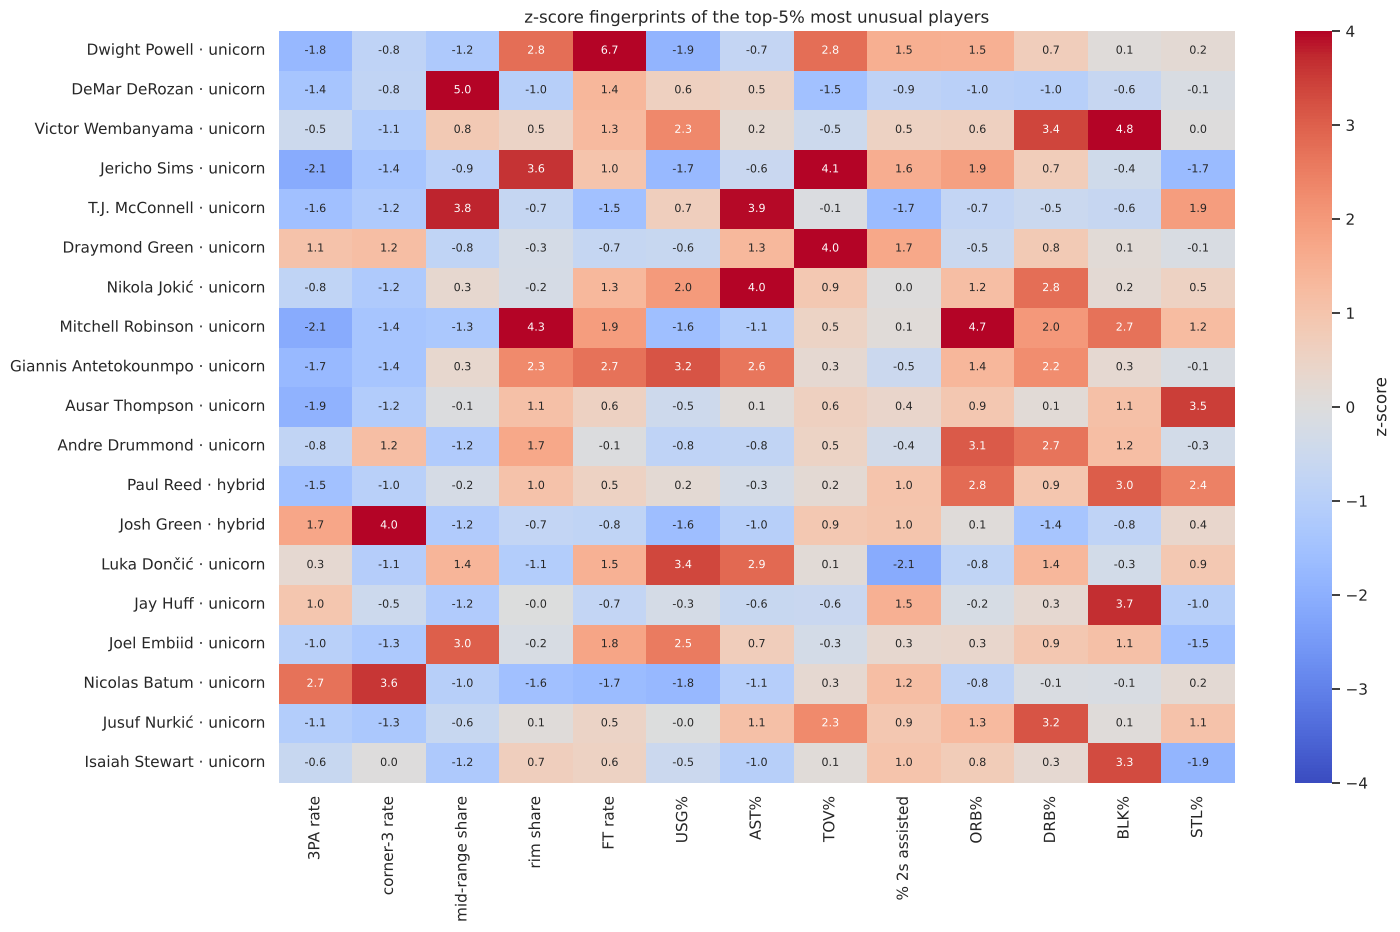

In [11]:
fp = pd.DataFrame(Z[top_idx], columns=[LABEL[f] for f in FEAT],
                  index=[f'{names[i]} · {category[i].split()[-1]}' for i in top_idx])
fig, ax = plt.subplots(figsize=(15, 0.42 * len(fp) + 1.5))
sns.heatmap(fp, annot=True, fmt='.1f', cmap='coolwarm', center=0, vmin=-4, vmax=4, annot_kws={'size': 8},
            cbar_kws={'label': 'z-score'}, ax=ax)
ax.set(title='z-score fingerprints of the top-5% most unusual players', xlabel='', ylabel='')
plt.tight_layout(); plt.show()

### Findings: Unicorns vs. border players
- **The three anomaly measures agree strongly with each other** (Spearman ≈ 0.66–0.79), but **the silhouette is
  essentially unrelated to them** (|ρ| ≤ 0.24). Being *unusual* and being *between archetypes* are two different
  phenomena, which is exactly why they must be measured separately. In the quadrant plot the cloud fills the space
  rather than lying on a diagonal.
- **17 of the 19 top-5% players are statistical unicorns**: clear members of an archetype, but extreme versions of it.
  Only **2 are unique hybrids**: Paul Reed (Hub Big, leaning toward the rim-runners) and Josh Green (the league's
  highest corner-3 rate, between Spot-Up Floor Spacer and Defensive Disruptor).
- **Every unicorn is an extreme specialist** (at least one |z| ≥ 3): at the very top of the ranking, unusualness always
  involves at least one extreme skill. The **rare-combination** profiles, unusual overall but without a single extreme
  feature, appear just below the cut: Lonzo Ball (rank 20), Day'Ron Sharpe (21), Jayson Tatum (23), Jimmy Butler (27)
  and Zion Williamson (29).
- **Extreme specialists** are defined by one skill far outside the league's range, e.g. Dwight Powell's free-throw
  rate, DeMar DeRozan's mid-range share, T.J. McConnell's assist rate, Victor Wembanyama's block rate and Mitchell
  Robinson's offensive rebounding.
- **Superstars appear as unicorns when their usage and creation load is extreme for their archetype**: Jokić,
  Giannis and Dončić are each the most extreme member of their role, not a different role.
- **Being in-between does not make a player unusual.** The 78 border players have a median anomaly score of 0.51,
  practically the league median (0.48), and only 2 of them reach the top 5%. Jalen Brunson and Stephen Curry are border
  players with ordinary anomaly scores. Kevin Durant, by contrast, is *not* a border player (silhouette 0.09) but is a
  near-unicorn (rank ≈ 26): a rare scoring profile that is still closest to the Primary Creators.

---
## 6. Robustness

**Goal.** Check that the anomaly ranking does not depend on two arbitrary choices:
1. **`min_samples`** in the persistence measure (4, 6, 10 instead of 6);
2. **the feature space** (power-transformed instead of standardised features).

**Measures.** Spearman correlation of the anomaly score with the baseline score, and the overlap of the top-5% lists
(how many of the baseline's top players are also in the alternative's top 5%).

**What to look for.** High rank correlation and large overlap mean the unicorn list is a property of the players, not of
the parameters.

In [12]:
def anomaly_score(F, ms):
    Dm = cdist(F, F)
    kd = np.sort(Dm, axis=1)[:, ms - 1]
    v = np.maximum(Dm, kd[None, :]); np.fill_diagonal(v, np.inf)
    ee = np.minimum(kd, v.min(axis=1))
    c = pd.DataFrame(F).groupby(archetype).mean()
    dc = np.linalg.norm(F - c.loc[archetype].values, axis=1)
    return (rank(ee) + rank(dc) + rank(np.abs(F).max(axis=1))) / 3

k_top = is_anom.sum()
base_top = set(np.argsort(-score)[:k_top])
rows = []
for label, F, ms in [('min_samples = 4', Z, 4), ('min_samples = 10', Z, 10),
                     ('power-transformed features', power[FEAT].values, MIN_SAMPLES)]:
    alt = anomaly_score(F, ms)
    rows.append({'alternative': label, 'Spearman ρ with baseline': spearmanr(score, alt)[0],
                 f'top-{k_top} overlap': len(base_top & set(np.argsort(-alt)[:k_top]))})
pd.DataFrame(rows).set_index('alternative').round(3)

,Spearman ρ with baseline,top-19 overlap
alternative,,
min_samples = 4,0.993,18
min_samples = 10,0.990,17
power-transformed features,0.779,8


### Findings: Robustness
- **Changing `min_samples` barely changes the ranking**: the persistence measure is driven by the overall sparsity of a
  player's neighbourhood, not by the exact density threshold.
- **The power-transformed space agrees much less** (ρ ≈ 0.78, only 8 of 19 shared). The players it drops are exactly the
  extreme specialists of long-tailed stats: Wembanyama (BLK%), Mitchell Robinson (ORB%), Jokić (AST%), Giannis and
  Dončić (usage), and several bigs. It replaces them with perimeter shooting profiles that have no single extreme feature
  (Tim Hardaway Jr., Cam Thomas, Sam Hauser, Gary Trent Jr.). This is the expected effect: the power transform
  compresses long right tails, which is right for clustering but hides the extremes an anomaly analysis is looking
  for. It confirms the choice of the standardised space here.

---
## 7. The Unicorns on the Player Map, and Export

**Goal.** Place the unicorns and unique hybrids on the PC1 × PC2 map from the PCA notebook, with archetypes in the
background.

**What to look for.** Unicorns should sit at the **outer edges** of the map or of their archetype's region; border
players should sit in the **interior**, where archetype regions meet.

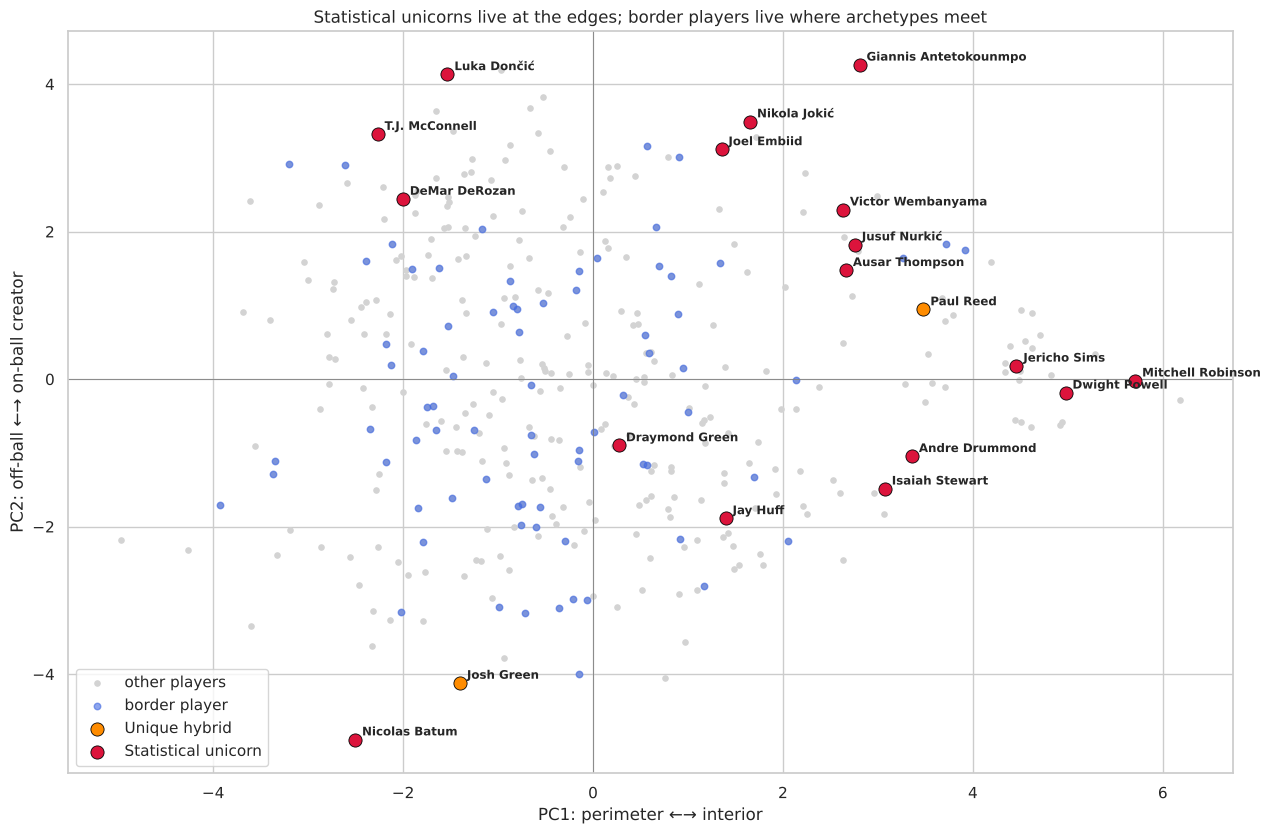

median distance from the centre of the map (PC1–PC2):
Border player          2.08
Statistical unicorn    3.52
Typical                2.49
Unique hybrid          3.98


In [13]:
fig, ax = plt.subplots(figsize=(13, 8.5))
ax.scatter(arch['PC1'], arch['PC2'], s=14, color='lightgrey', label='other players')
bm = category == 'Border player'
ax.scatter(arch['PC1'][bm], arch['PC2'][bm], s=22, color='royalblue', alpha=0.6, label='border player')
for c in ['Unique hybrid', 'Statistical unicorn']:
    m = category == c
    ax.scatter(arch['PC1'][m], arch['PC2'][m], s=90, color=CAT_PAL[c], edgecolor='black', linewidth=0.6,
               label=c, zorder=4)
for i in np.where(is_anom)[0]:
    ax.annotate(names[i], (arch['PC1'][i], arch['PC2'][i]), xytext=(5, 3), textcoords='offset points',
                fontsize=8.5, weight='bold', zorder=5)
ax.axhline(0, color='grey', lw=0.6); ax.axvline(0, color='grey', lw=0.6)
ax.set(xlabel='PC1: perimeter ←→ interior', ylabel='PC2: off-ball ←→ on-ball creator',
       title='Statistical unicorns live at the edges; border players live where archetypes meet')
ax.legend(loc='lower left'); plt.tight_layout(); plt.show()

dist_origin = np.hypot(arch['PC1'], arch['PC2'])
print('median distance from the centre of the map (PC1–PC2):')
print(pd.Series(dist_origin).groupby(category).median().round(2).to_string())

### Findings: Location on the map
- Most unicorns sit far from the centre of the map: at the interior edge (Robinson, Powell, Sims), the creator edge
  (Dončić, Giannis, Jokić, McConnell) or the extreme perimeter (Batum, Josh Green).
- **Draymond Green is the instructive exception.** On PC1 × PC2 Draymond sits close to the centre, yet ranks 6th in the
  league for unusualness. The extreme features (TOV% z = +4.0, combined with lead-guard passing and big-man rebounding
  on modest usage) live in dimensions the 2-D map does not show. This is a reminder that anomalies were measured in the
  full 13-feature space, not on the map.
- Border players sit much closer to the centre, where archetype regions meet (compare the printed median distances).
  The two groups occupy different *parts* of the style space, one more confirmation that they are different phenomena.

### Export

**Goal.** Save one row per player with all anomaly measures, the classification and the signature features, for the
validation notebook and for reporting. Only the results computed here are stored, keyed by `player_id` in the same row
order as `archetypes.csv`; archetype, family, position, silhouette and map coordinates are read from that file rather
than copied.

| Column | Meaning |
|---|---|
| `eps_exit`, `controlling_neighbour` | DBSCAN noise persistence and the player that ends it |
| `dist_to_centroid` | distance to the archetype centroid (standardised space) |
| `max_abs_z`, `max_z_feature`, `n_features_abs_z_ge_3` | z-score extremes |
| `anomaly_score` | mean percentile rank of the three measures |
| `category`, `unicorn_type` | Statistical unicorn / Unique hybrid / Border player / Typical; extreme specialist / rare combination |
| `signature` | the three most extreme features, with raw values and z-scores |

In [14]:
out = DATA / 'processed'
result = pd.concat([arch[['player_id', 'player']],
                    pd.DataFrame({'eps_exit': eps_exit.round(3),
                                  'controlling_neighbour': [('' if a == -1 else names[a]) for a in anchor],
                                  'dist_to_centroid': d_cent.round(3), 'max_abs_z': max_z.round(2),
                                  'max_z_feature': max_feat, 'n_features_abs_z_ge_3': n_extreme,
                                  'anomaly_score': score.round(4), 'category': category,
                                  'unicorn_type': unicorn_type,
                                  'signature': [signature(i) for i in range(len(Z))]})], axis=1)
result.to_csv(out / 'anomalies.csv', index=False)
print('saved', out / 'anomalies.csv', result.shape)
result.sort_values('anomaly_score', ascending=False)[['player', 'category', 'unicorn_type',
                                                      'anomaly_score', 'signature']].head(8)

saved ../data/processed/anomalies.csv (379, 12)


,player,category,unicorn_type,anomaly_score,signature
270,Dwight Powell,Statistical unicorn,extreme specialist,1.0000,"FT rate 1.11 (z +6.7), rim share 0.68 (z +2.8), TOV% 21.40 (z +2.8)"
79,DeMar DeRozan,Statistical unicorn,extreme specialist,0.9921,"mid-range share 0.58 (z +5.0), TOV% 7.40 (z -1.5), 3PA rate 0.15 (z -1.4)"
357,Victor Wembanyama,Statistical unicorn,extreme specialist,0.9912,"BLK% 9.40 (z +4.8), DRB% 33.90 (z +3.4), USG% 32.40 (z +2.3)"
218,T.J. McConnell,Statistical unicorn,extreme specialist,0.9886,"AST% 50.00 (z +3.9), mid-range share 0.47 (z +3.8), STL% 2.80 (z +1.9)"
313,Jericho Sims,Statistical unicorn,extreme specialist,0.9886,"TOV% 25.80 (z +4.1), rim share 0.82 (z +3.6), 3PA rate 0.00 (z -2.1)"
125,Draymond Green,Statistical unicorn,extreme specialist,0.9859,"TOV% 25.50 (z +4.0), % 2s assisted 0.84 (z +1.7), AST% 27.30 (z +1.3)"
176,Nikola Jokić,Statistical unicorn,extreme specialist,0.9745,"AST% 50.30 (z +4.0), DRB% 30.40 (z +2.8), USG% 30.40 (z +2.0)"
290,Mitchell Robinson,Statistical unicorn,extreme specialist,0.9701,"ORB% 23.90 (z +4.7), rim share 0.92 (z +4.3), BLK% 6.10 (z +2.7)"


---
## Summary

| Question | Answer |
|---|---|
| How is "unusual" measured? | Three complementary measures in the standardised space: DBSCAN noise persistence (ε-exit, computed exactly), distance to the archetype centroid, and the largest absolute z-score |
| Do the measures agree? | Yes, strongly with one another (ρ ≈ 0.66–0.79), so they capture a common notion of "far from others" |
| Unusual vs. in-between | **Different phenomena**: the silhouette is essentially uncorrelated with the anomaly measures |
| Who are the unicorns? | The top 5% by anomaly score: **17 statistical unicorns**, all extreme specialists of an existing archetype (e.g. Powell, DeRozan, Wembanyama, McConnell, Draymond Green, Jokić, Giannis, Dončić), plus **2 unique hybrids** (Paul Reed, Josh Green) |
| Border players | About as unusual as the average player (median score 0.51 vs. 0.48) and closest to the centre of the map (e.g. Brunson, Curry): versatile, not unusual |
| Robust? | Insensitive to `min_samples` (ρ ≈ 0.99, 17–18 of 19 shared); the power-transformed space hides long-tail specialists, which supports the standardised space |

**Next: `06_Validation.ipynb`.** Formal comparison of families and archetypes with listed and play-by-play positions
(agreement beyond chance, confusion matrix, variance explained, supervised prediction, silhouette), where the
unicorns and border players come from, and a final summary of what data-driven archetypes add to the five-position
system.